In [1]:
# Instalar Java (Spark lo necesita) y PySpark
!apt-get install -y openjdk-17-jdk-headless -qq > /dev/null
!pip install -q pyspark==3.5.3

import os
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 317.3/317.3 MB 4.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 200.5/200.5 kB 21.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dataproc-spark-connect 1.1.0 requires pyspark[connect]~=4.0.0, but you have pyspark 3.5.3 which is incompatible.


In [2]:
from pyspark.sql import SparkSession
import psutil

spark = (SparkSession.builder
         .appName("SmartRetail_BigData")
         .master("local[*]")
         .config("spark.driver.memory", "6g")
         .getOrCreate())

print("Versión de Spark:     ", spark.version)
print("Núcleos de CPU:       ", psutil.cpu_count())
print("RAM total (GB):       ", round(psutil.virtual_memory().total / 1e9, 1))
print("Paralelismo de Spark: ", spark.sparkContext.defaultParallelism)

Versión de Spark:      3.5.3
Núcleos de CPU:        2
RAM total (GB):        13.6
Paralelismo de Spark:  2


In [3]:
from google.colab import drive
drive.mount('/content/drive')

# Disco local de Colab: rápido, para procesar y medir tiempos
LOCAL = "/content/smartretail"

# Google Drive: permanente, para logs y resultados del experimento
DRIVE = "/content/drive/MyDrive/SmartRetail_BigData"

for carpeta in [f"{LOCAL}/raw", f"{LOCAL}/processed", f"{DRIVE}/logs", f"{DRIVE}/resultados"]:
    os.makedirs(carpeta, exist_ok=True)

print("Carpetas listas")

Mounted at /content/drive
Carpetas listas


In [5]:
from pyspark.sql import functions as F

ESTADOS = ["RECOGIDO", "EN TRANSITO", "EN CENTRO DE DISTRIBUCION", "EN REPARTO", "ENTREGADO"]
TIPOS   = ["ESCANEO", "ACTUALIZACION_ESTADO", "INCIDENCIA"]
UBIGEOS = ["150122", "150131", "150140", "150132", "150117", "070101",
           "040101", "080101", "130101", "140101", "200101"]

def elegir(lista, semilla):
    """Elige un valor al azar de una lista, para cada fila."""
    arreglo = F.array(*[F.lit(x) for x in lista])
    return F.element_at(arreglo, (F.rand(semilla) * len(lista)).cast("int") + 1)

def generar_eventos(n, semilla=42):
    inicio = F.unix_timestamp(F.lit("2025-01-01 00:00:00"))
    pedido = (F.col("id") / 5).cast("long")   # número de pedido
    paso   = F.col("id") % 5                  # etapa del envío: 0 a 4

    def azar_pedido(k):
        """Número al azar, pero igual para todos los eventos del mismo pedido."""
        return F.abs(F.xxhash64(pedido, F.lit(semilla + k)))

    df = (spark.range(n)
          .withColumn("event_id",    F.concat(F.lit("EVT-"), F.lpad(F.col("id").cast("string"), 8, "0")))
          .withColumn("order_id",    F.concat(F.lit("PED-"), F.lpad(pedido.cast("string"), 7, "0")))
          .withColumn("customer_id", F.concat(F.lit("CLI-"), F.lpad((azar_pedido(0) % 200).cast("string"), 3, "0")))
          .withColumn("event_timestamp", F.from_unixtime(
                          inicio
                          + azar_pedido(1) % (638 * 86400)              # fecha del pedido
                          + paso * 86400                                # un día por etapa
                          + (F.rand(semilla) * 3600).cast("long")))     # hora variable
          .withColumn("event_type",      elegir(TIPOS, semilla + 2))
          .withColumn("shipment_status", F.element_at(F.array(*[F.lit(x) for x in ESTADOS]), (paso + 1).cast("int")))
          .withColumn("warehouse_id",    F.concat(F.lit("ALM-0"), (azar_pedido(2) % 3 + 1).cast("string")))
          .withColumn("location_id",     F.element_at(F.array(*[F.lit(x) for x in UBIGEOS]), (azar_pedido(3) % 11 + 1).cast("int")))
          .withColumn("carrier_id",      F.concat(F.lit("TR-00"), (azar_pedido(4) % 4 + 1).cast("string")))
          .withColumn("r", F.rand(semilla + 9)))

    # Errores sembrados a propósito (1 % cada uno)
    df = (df
          .withColumn("order_id", F.when(F.col("r") < 0.01, None).otherwise(F.col("order_id")))
          .withColumn("shipment_status", F.when((F.col("r") >= 0.01) & (F.col("r") < 0.02), "ESTADO_INVALIDO")
                                          .otherwise(F.col("shipment_status")))
          .withColumn("event_timestamp", F.when((F.col("r") >= 0.02) & (F.col("r") < 0.03),
                                                F.date_format(F.to_timestamp("event_timestamp"), "dd/MM/yyyy HH:mm:ss"))
                                          .otherwise(F.col("event_timestamp"))))

    # Duplicados: se repite cerca del 2 % de los eventos
    duplicados = df.sample(fraction=0.02, seed=semilla)
    return df.unionByName(duplicados).drop("id", "r")

eventos = generar_eventos(1000)
eventos.orderBy("event_id").show(10, truncate=False)
print("Total de eventos:", eventos.count())

+------------+-----------+-----------+-------------------+--------------------+-------------------------+------------+-----------+----------+
|event_id    |order_id   |customer_id|event_timestamp    |event_type          |shipment_status          |warehouse_id|location_id|carrier_id|
+------------+-----------+-----------+-------------------+--------------------+-------------------------+------------+-----------+----------+
|EVT-00000000|PED-0000000|CLI-043    |2026-05-22 11:39:00|INCIDENCIA          |RECOGIDO                 |ALM-01      |150132     |TR-002    |
|EVT-00000001|PED-0000000|CLI-043    |2026-05-23 11:32:25|INCIDENCIA          |EN TRANSITO              |ALM-01      |150132     |TR-002    |
|EVT-00000002|PED-0000000|CLI-043    |2026-05-24 11:51:48|ACTUALIZACION_ESTADO|EN CENTRO DE DISTRIBUCION|ALM-01      |150132     |TR-002    |
|EVT-00000003|PED-0000000|CLI-043    |2026-05-25 11:17:38|INCIDENCIA          |EN REPARTO               |ALM-01      |150132     |TR-002    |
|EVT-0

In [6]:
import time

ESCALAS = {
    "EXP-01":   100_000,
    "EXP-02":   500_000,
    "EXP-03": 1_000_000,
    "EXP-04": 5_000_000,
}

for exp, n in ESCALAS.items():
    t0 = time.time()
    (generar_eventos(n)
        .write.mode("overwrite")
        .option("header", True)
        .csv(f"{LOCAL}/raw/{exp}"))
    print(f"{exp}: {n:>9,} eventos base generados en {time.time() - t0:5.1f} s")

EXP-01:   100,000 eventos base generados en   2.5 s
EXP-02:   500,000 eventos base generados en   3.5 s
EXP-03: 1,000,000 eventos base generados en   5.1 s
EXP-04: 5,000,000 eventos base generados en  15.5 s


In [7]:
for exp in ESCALAS:
    filas = spark.read.option("header", True).csv(f"{LOCAL}/raw/{exp}").count()
    print(f"{exp}: {filas:>10,} filas en raw")

!du -sh /content/smartretail/raw/*

EXP-01:    102,092 filas en raw
EXP-02:    510,103 filas en raw
EXP-03:  1,020,121 filas en raw
EXP-04:  5,100,089 filas en raw
10M	/content/smartretail/raw/EXP-01
50M	/content/smartretail/raw/EXP-02
99M	/content/smartretail/raw/EXP-03
495M	/content/smartretail/raw/EXP-04


In [8]:
def procesar(exp):
    """Lee los eventos crudos, aplica las reglas de calidad y guarda en Parquet."""
    crudo = spark.read.option("header", True).csv(f"{LOCAL}/raw/{exp}")

    limpio = (crudo
        # RC-01 Unicidad: un evento repetido se conserva una sola vez
        .dropDuplicates(["event_id"])
        # RC-02 Completitud: sin pedido no se sabe de qué envío es el evento
        .filter(F.col("order_id").isNotNull())
        # RC-03 Validez: solo estados logísticos permitidos
        .filter(F.col("shipment_status").isin(ESTADOS))
        # RC-04 Consistencia: se aceptan los dos formatos de fecha y se unifican
        .withColumn("event_ts", F.coalesce(
            F.to_timestamp("event_timestamp", "yyyy-MM-dd HH:mm:ss"),
            F.to_timestamp("event_timestamp", "dd/MM/yyyy HH:mm:ss")))
        .filter(F.col("event_ts").isNotNull())
        .drop("event_timestamp")
        # Columnas para particionar y auditar
        .withColumn("anio", F.year("event_ts"))
        .withColumn("mes",  F.month("event_ts"))
        .withColumn("processing_date", F.current_date()))

    (limpio.write.mode("overwrite")
        .partitionBy("anio", "mes")
        .parquet(f"{LOCAL}/processed/{exp}"))

    return crudo

crudo = procesar("EXP-01")
procesado = spark.read.parquet(f"{LOCAL}/processed/EXP-01")

print("Filas en raw:          ", crudo.count())
print("Duplicados (RC-01):    ", crudo.count() - crudo.dropDuplicates(["event_id"]).count())
print("Pedido nulo (RC-02):   ", crudo.filter(F.col("order_id").isNull()).count())
print("Estado inválido (RC-03):", crudo.filter(~F.col("shipment_status").isin(ESTADOS)).count())
print("Fecha dd/MM (RC-04):   ", crudo.filter(F.col("event_timestamp").like("__/__/%")).count())
print("Filas en processed:    ", procesado.count())

Filas en raw:           102092
Duplicados (RC-01):     2092
Pedido nulo (RC-02):    1013
Estado inválido (RC-03): 1033
Fecha dd/MM (RC-04):    1004
Filas en processed:     97983


In [10]:
import threading, datetime
import pandas as pd

class Monitor:
    """Mide CPU y RAM en segundo plano mientras corre el procesamiento."""
    def __init__(self, intervalo=0.5):
        self.intervalo = intervalo
        self.cpu, self.ram = [], []
        self._parar = threading.Event()

    def _medir(self):
        while not self._parar.is_set():
            self.cpu.append(psutil.cpu_percent(interval=None))
            self.ram.append(psutil.virtual_memory().used / 1e9)
            time.sleep(self.intervalo)

    def __enter__(self):
        psutil.cpu_percent(interval=None)          # inicializa el contador de CPU
        self._hilo = threading.Thread(target=self._medir)
        self._hilo.start()
        return self

    def __exit__(self, *args):
        self._parar.set()
        self._hilo.join()

In [11]:
REPETICIONES = 3
registros = []
run = 1

# Calentamiento: una ejecución que no se registra
procesar("EXP-01")

for exp in ESCALAS:
    filas_raw = spark.read.option("header", True).csv(f"{LOCAL}/raw/{exp}").count()

    for rep in range(1, REPETICIONES + 1):
        estado = "EXITOSO"
        with Monitor() as m:
            t0 = time.time()
            try:
                procesar(exp)
            except Exception as e:
                estado = f"ERROR: {str(e)[:100]}"
            tiempo = time.time() - t0

        filas_proc = spark.read.parquet(f"{LOCAL}/processed/{exp}").count()
        registros.append({
            "run_id": f"RUN-{run:02d}",
            "escenario": exp,
            "repeticion": rep,
            "filas_raw": filas_raw,
            "filas_procesadas": filas_proc,
            "filas_rechazadas": filas_raw - filas_proc,
            "tiempo_s": round(tiempo, 2),
            "throughput_filas_s": round(filas_raw / tiempo),
            "cpu_prom_pct": round(sum(m.cpu) / len(m.cpu), 1),
            "cpu_max_pct": max(m.cpu),
            "ram_max_gb": round(max(m.ram), 2),
            "fecha_hora": datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
            "spark": spark.version,
            "estado": estado,
        })
        print(f"RUN-{run:02d} {exp} rep {rep}: {tiempo:6.1f} s | {filas_raw / tiempo:>9,.0f} filas/s | {estado}")
        run += 1

resultados = pd.DataFrame(registros)
resultados.to_csv(f"{DRIVE}/logs/ejecuciones.csv", index=False)
resultados

RUN-01 EXP-01 rep 1:    3.9 s |    26,434 filas/s | EXITOSO
RUN-02 EXP-01 rep 2:    2.8 s |    36,158 filas/s | EXITOSO
RUN-03 EXP-01 rep 3:    2.4 s |    41,823 filas/s | EXITOSO
RUN-04 EXP-02 rep 1:    8.2 s |    61,982 filas/s | EXITOSO
RUN-05 EXP-02 rep 2:    6.6 s |    77,463 filas/s | EXITOSO
RUN-06 EXP-02 rep 3:    7.0 s |    73,053 filas/s | EXITOSO
RUN-07 EXP-03 rep 1:   11.5 s |    88,745 filas/s | EXITOSO
RUN-08 EXP-03 rep 2:   11.6 s |    87,939 filas/s | EXITOSO
RUN-09 EXP-03 rep 3:   11.4 s |    89,349 filas/s | EXITOSO
RUN-10 EXP-04 rep 1:   53.5 s |    95,255 filas/s | EXITOSO
RUN-11 EXP-04 rep 2:   51.7 s |    98,581 filas/s | EXITOSO
RUN-12 EXP-04 rep 3:   51.9 s |    98,180 filas/s | EXITOSO


,run_id,escenario,repeticion,filas_raw,filas_procesadas,filas_rechazadas,tiempo_s,throughput_filas_s,cpu_prom_pct,cpu_max_pct,ram_max_gb,fecha_hora,spark,estado
0,RUN-01,EXP-01,1,102092,97983,4109,3.86,26434,87.2,100.0,2.34,2026-10-11 06:09:19,3.5.3,EXITOSO
1,RUN-02,EXP-01,2,102092,97983,4109,2.82,36158,82.3,100.0,2.51,2026-10-11 06:09:22,3.5.3,EXITOSO
2,RUN-03,EXP-01,3,102092,97983,4109,2.44,41823,79.4,100.0,2.52,2026-10-11 06:09:25,3.5.3,EXITOSO
3,RUN-04,EXP-02,1,510103,489887,20216,8.23,61982,93.8,100.0,2.58,2026-10-11 06:09:34,3.5.3,EXITOSO
4,RUN-05,EXP-02,2,510103,489887,20216,6.59,77463,92.1,100.0,2.59,2026-10-11 06:09:42,3.5.3,EXITOSO
5,RUN-06,EXP-02,3,510103,489887,20216,6.98,73053,92.4,100.0,3.13,2026-10-11 06:09:49,3.5.3,EXITOSO
6,RUN-07,EXP-03,1,1020121,979949,40172,11.50,88745,99.7,100.0,3.16,2026-10-11 06:10:01,3.5.3,EXITOSO
7,RUN-08,EXP-03,2,1020121,979949,40172,11.60,87939,95.4,100.0,3.26,2026-10-11 06:10:14,3.5.3,EXITOSO
8,RUN-09,EXP-03,3,1020121,979949,40172,11.42,89349,95.3,100.0,3.27,2026-10-11 06:10:26,3.5.3,EXITOSO
9,RUN-10,EXP-04,1,5100089,4899984,200105,53.54,95255,94.5,100.0,4.37,2026-10-11 06:11:22,3.5.3,EXITOSO


,filas_raw,tiempo_prom_s,tiempo_desv_s,throughput_prom,cpu_prom_pct,ram_max_gb,cv_tiempo_pct
escenario,,,,,,,
EXP-01,102092,3.04,0.74,34805.00,82.97,2.52,24.3
EXP-02,510103,7.27,0.86,70832.67,92.77,3.13,11.8
EXP-03,1020121,11.51,0.09,88677.67,96.80,3.27,0.8
EXP-04,5100089,52.41,0.99,97338.67,94.17,4.38,1.9


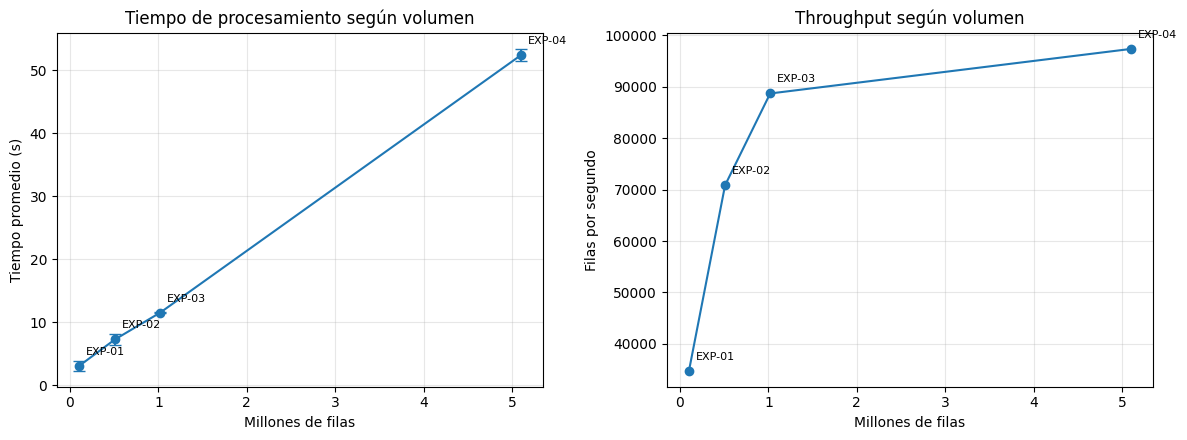

In [12]:
import matplotlib.pyplot as plt

resumen = (resultados.groupby("escenario")
           .agg(filas_raw=("filas_raw", "first"),
                tiempo_prom_s=("tiempo_s", "mean"),
                tiempo_desv_s=("tiempo_s", "std"),
                throughput_prom=("throughput_filas_s", "mean"),
                cpu_prom_pct=("cpu_prom_pct", "mean"),
                ram_max_gb=("ram_max_gb", "max"))
           .round(2))
resumen["cv_tiempo_pct"] = (100 * resumen["tiempo_desv_s"] / resumen["tiempo_prom_s"]).round(1)
resumen.to_csv(f"{DRIVE}/resultados/resumen_escenarios.csv")
display(resumen)

millones = resumen["filas_raw"] / 1e6
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.errorbar(millones, resumen["tiempo_prom_s"], yerr=resumen["tiempo_desv_s"],
             marker="o", capsize=4)
ax1.set_title("Tiempo de procesamiento según volumen")
ax1.set_xlabel("Millones de filas")
ax1.set_ylabel("Tiempo promedio (s)")
ax1.grid(alpha=0.3)

ax2.plot(millones, resumen["throughput_prom"], marker="o")
ax2.set_title("Throughput según volumen")
ax2.set_xlabel("Millones de filas")
ax2.set_ylabel("Filas por segundo")
ax2.grid(alpha=0.3)

for ax, col in [(ax1, "tiempo_prom_s"), (ax2, "throughput_prom")]:
    for exp, x, y in zip(resumen.index, millones, resumen[col]):
        ax.annotate(exp, (x, y), textcoords="offset points", xytext=(5, 8), fontsize=8)

plt.tight_layout()
plt.savefig(f"{DRIVE}/resultados/escalabilidad.png", dpi=150)
plt.show()

In [13]:
spark.read.parquet(f"{LOCAL}/processed/EXP-04").createOrReplaceTempView("eventos")

def medir(sql, titulo):
    spark.sql(sql).collect()                    # primera vez: calentamiento
    t0 = time.time()
    filas = spark.sql(sql).collect()
    print(f"{titulo:<45} {time.time() - t0:6.2f} s  ({len(filas)} filas)")
    return spark.sql(sql)

# 1. Análisis del negocio
medir("""SELECT shipment_status, COUNT(*) AS eventos
         FROM eventos GROUP BY shipment_status""", "Eventos por estado").show()

medir("""SELECT carrier_id, COUNT(DISTINCT order_id) AS pedidos_entregados
         FROM eventos WHERE shipment_status = 'ENTREGADO'
         GROUP BY carrier_id ORDER BY carrier_id""", "Pedidos entregados por transportista").show()

# 2. Particionamiento: consultar un mes
medir("""SELECT COUNT(*) FROM eventos WHERE anio = 2025 AND mes = 3""",
      "Un mes, filtrando por la partición")
medir("""SELECT COUNT(*) FROM eventos
         WHERE event_ts >= '2025-03-01' AND event_ts < '2025-04-01'""",
      "Un mes, filtrando por la fecha (sin partición)")

# 3. Latencia de rastreo: buscar un pedido
medir("""SELECT order_id, event_ts, shipment_status, carrier_id
         FROM eventos WHERE order_id = 'PED-0500000' ORDER BY event_ts""",
      "Rastreo de un pedido (RNF-04)").show(truncate=False)

Eventos por estado                              0.70 s  (5 filas)
+--------------------+-------+
|     shipment_status|eventos|
+--------------------+-------+
|         EN TRANSITO| 980181|
|            RECOGIDO| 979984|
|           ENTREGADO| 979800|
|          EN REPARTO| 980199|
|EN CENTRO DE DIST...| 979820|
+--------------------+-------+

Pedidos entregados por transportista            3.66 s  (4 filas)
+----------+------------------+
|carrier_id|pedidos_entregados|
+----------+------------------+
|    TR-001|            245106|
|    TR-002|            244781|
|    TR-003|            244944|
|    TR-004|            244969|
+----------+------------------+

Un mes, filtrando por la partición              0.09 s  (1 filas)
Un mes, filtrando por la fecha (sin partición)   0.52 s  (1 filas)
Rastreo de un pedido (RNF-04)                   1.47 s  (5 filas)
+-----------+-------------------+-------------------------+----------+
|order_id   |event_ts           |shipment_status          |ca

In [14]:
(spark.read.parquet(f"{LOCAL}/processed/EXP-04")
    .repartitionByRange(8, "order_id")
    .sortWithinPartitions("order_id")
    .write.mode("overwrite")
    .parquet(f"{LOCAL}/processed/EXP-04_por_pedido"))

spark.read.parquet(f"{LOCAL}/processed/EXP-04_por_pedido").createOrReplaceTempView("eventos_por_pedido")

medir("""SELECT order_id, event_ts, shipment_status, carrier_id
         FROM eventos            WHERE order_id = 'PED-0500000' ORDER BY event_ts""",
      "Rastreo ANTES (datos por fecha)")
medir("""SELECT order_id, event_ts, shipment_status, carrier_id
         FROM eventos_por_pedido WHERE order_id = 'PED-0500000' ORDER BY event_ts""",
      "Rastreo DESPUÉS (datos por pedido)").show(truncate=False)

Rastreo ANTES (datos por fecha)                 1.16 s  (5 filas)
Rastreo DESPUÉS (datos por pedido)              0.14 s  (5 filas)
+-----------+-------------------+-------------------------+----------+
|order_id   |event_ts           |shipment_status          |carrier_id|
+-----------+-------------------+-------------------------+----------+
|PED-0500000|2026-07-02 03:44:54|RECOGIDO                 |TR-002    |
|PED-0500000|2026-07-03 03:36:11|EN TRANSITO              |TR-002    |
|PED-0500000|2026-07-04 03:11:53|EN CENTRO DE DISTRIBUCION|TR-002    |
|PED-0500000|2026-07-05 03:09:14|EN REPARTO               |TR-002    |
|PED-0500000|2026-07-06 03:35:09|ENTREGADO                |TR-002    |
+-----------+-------------------+-------------------------+----------+



In [15]:
rdd = spark.read.parquet(f"{LOCAL}/processed/EXP-04").rdd

t0 = time.time()
entregados_por_transportista = (rdd
    .filter(lambda fila: fila.shipment_status == "ENTREGADO")      # transformación
    .map(lambda fila: (fila.carrier_id, 1))                        # transformación
    .reduceByKey(lambda a, b: a + b)                               # transformación
    .sortByKey()                                                   # transformación
    .collect())                                                    # ACCIÓN
print(f"Tiempo con RDD: {time.time() - t0:.2f} s")

for transportista, total in entregados_por_transportista:
    print(transportista, total)

print("Particiones del RDD:", rdd.getNumPartitions())

Tiempo con RDD: 49.90 s
TR-001 245106
TR-002 244781
TR-003 244944
TR-004 244969
Particiones del RDD: 5


In [16]:
ciclo = spark.sql("""
    SELECT order_id, carrier_id,
           (unix_timestamp(MAX(CASE WHEN shipment_status = 'ENTREGADO' THEN event_ts END))
          - unix_timestamp(MIN(CASE WHEN shipment_status = 'RECOGIDO'  THEN event_ts END))) / 86400.0
           AS dias_ciclo
    FROM eventos
    GROUP BY order_id, carrier_id
    HAVING dias_ciclo IS NOT NULL
""")

print("Estadística descriptiva del tiempo de ciclo (días):")
ciclo.describe("dias_ciclo").show()

p25, p50, p75, p95 = ciclo.approxQuantile("dias_ciclo", [0.25, 0.5, 0.75, 0.95], 0.01)
print(f"Percentiles: P25={p25:.2f}  mediana={p50:.2f}  P75={p75:.2f}  P95={p95:.2f}")

print("Tiempo de ciclo por transportista:")
(ciclo.groupBy("carrier_id")
      .agg(F.count("*").alias("pedidos"),
           F.round(F.avg("dias_ciclo"), 3).alias("promedio_dias"),
           F.round(F.stddev("dias_ciclo"), 3).alias("desviacion_dias"))
      .orderBy("carrier_id")
      .show())

# Registro de las consultas (paso B8 a B10) en Drive
consultas = pd.DataFrame([
    {"consulta": "Eventos por estado (Spark SQL)",                 "tiempo_s": 0.70},
    {"consulta": "Pedidos entregados por transportista (Spark SQL)", "tiempo_s": 3.66},
    {"consulta": "Pedidos entregados por transportista (RDD)",       "tiempo_s": 49.90},
    {"consulta": "Un mes, filtrando por partición",                  "tiempo_s": 0.09},
    {"consulta": "Un mes, filtrando por fecha (sin partición)",      "tiempo_s": 0.52},
    {"consulta": "Rastreo de un pedido, datos por fecha",            "tiempo_s": 1.16},
    {"consulta": "Rastreo de un pedido, datos ordenados por pedido", "tiempo_s": 0.14},
])
consultas.to_csv(f"{DRIVE}/resultados/consultas.csv", index=False)
print("Consultas registradas en Drive")

Estadística descriptiva del tiempo de ciclo (días):
+-------+--------------------+
|summary|          dias_ciclo|
+-------+--------------------+
|  count|              960196|
|   mean|       4.00002402674|
| stddev|0.017015464381389015|
|    min|           3.9584491|
|    max|           4.0416435|
+-------+--------------------+

Percentiles: P25=3.99  mediana=4.00  P75=4.01  P95=4.03
Tiempo de ciclo por transportista:
+----------+-------+-------------+---------------+
|carrier_id|pedidos|promedio_dias|desviacion_dias|
+----------+-------+-------------+---------------+
|    TR-001| 240288|        4.000|          0.017|
|    TR-002| 239796|        4.000|          0.017|
|    TR-003| 239966|        4.000|          0.017|
|    TR-004| 240146|        4.000|          0.017|
+----------+-------+-------------+---------------+

Consultas registradas en Drive
